# 02 — Order book diagnostics

`book_series.csv` is written by the OCaml replay. Displayed size at a price is not a list of orders.

Mid is the integer average of best bid and best ask, truncated toward zero. Microprice is computed in the engine; this series stores mid, touch prices, touch quantities and spread. Spread is ask minus bid in price units.

synthetic: True rows: 4001
                mid  spread      bid_qty      ask_qty    imbalance
count  4.001000e+03  4001.0  4001.000000  4001.000000  4001.000000
mean   6.500008e+06    10.0    93.695326    91.620595     0.013447
std    7.206898e+00     0.0    25.416056    26.425698     0.221525
min    6.499989e+06    10.0    14.000000     1.000000    -0.744681
25%    6.500004e+06    10.0    74.000000    72.000000    -0.131579
50%    6.500008e+06    10.0    95.000000    92.000000     0.007874
75%    6.500014e+06    10.0   114.000000   111.000000     0.148148
max    6.500021e+06    10.0   149.000000   161.000000     0.977778


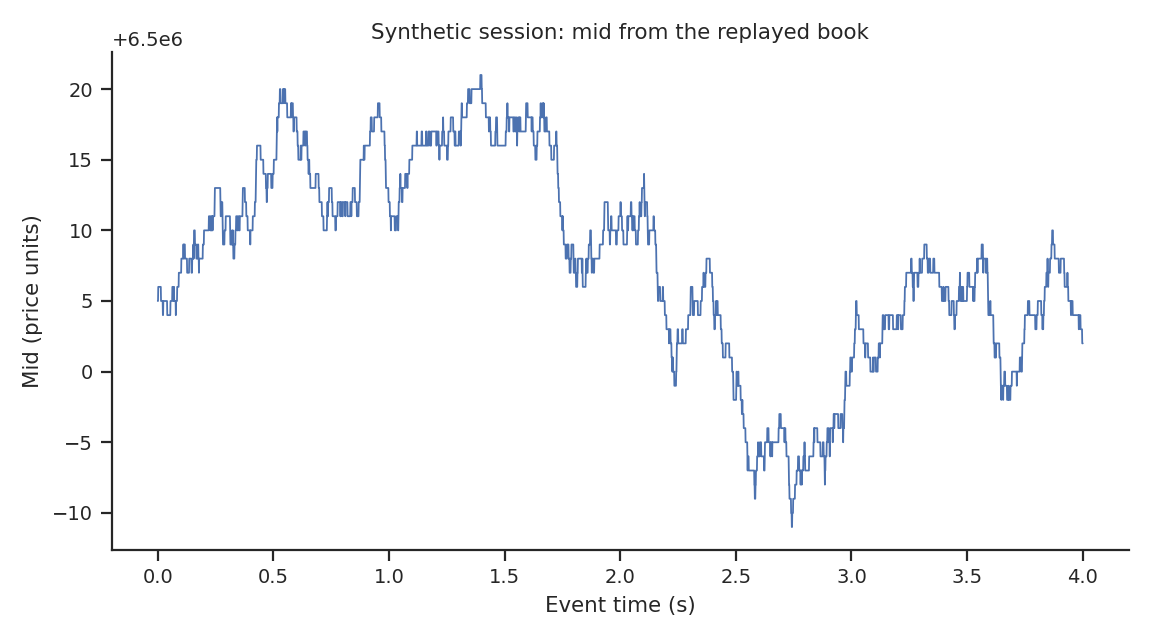

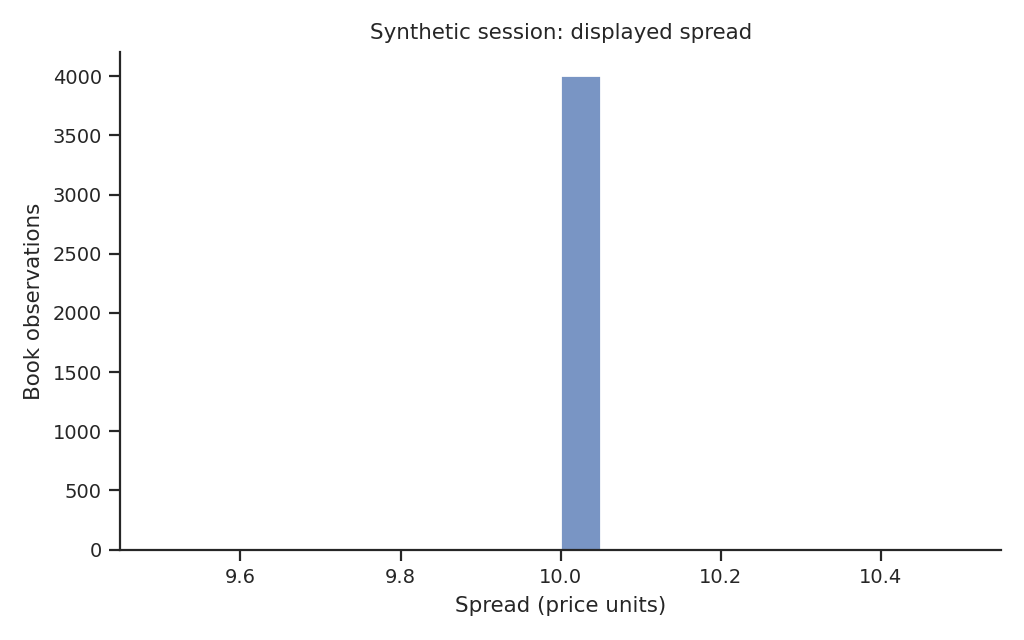

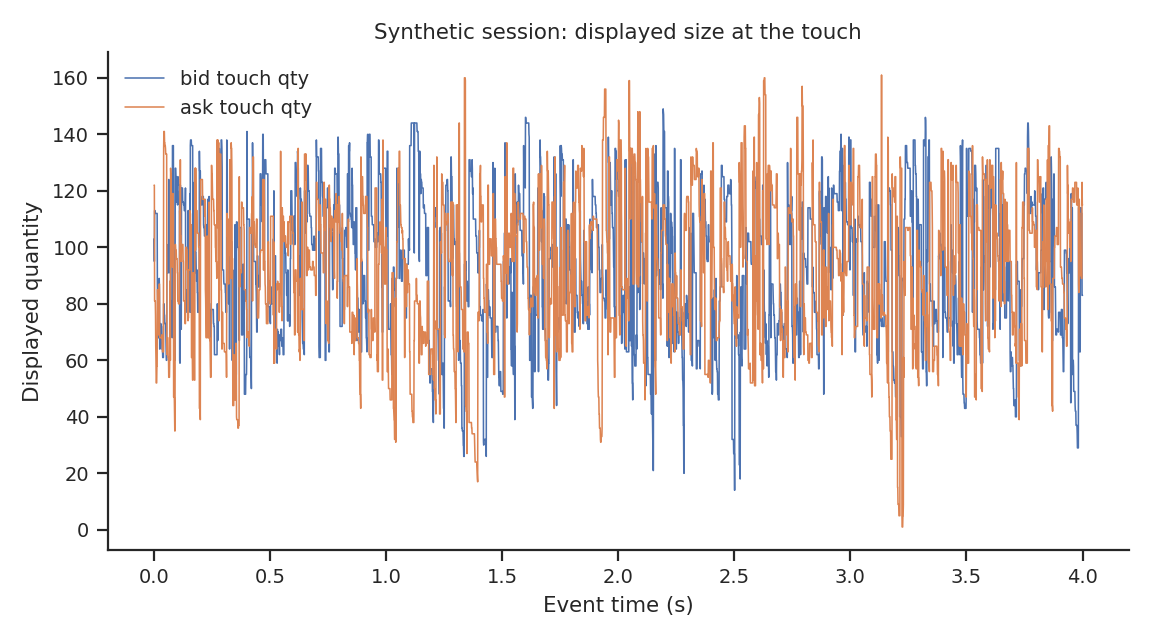

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd()
if not (ROOT / "scripts" / "analysis.py").is_file():
    raise SystemExit("run this notebook from the repository root")
sys.path.insert(0, str(ROOT / "scripts"))
import analysis
from IPython.display import Image, display

def show(name):
    display(Image(filename=str(analysis.FIG / f"{name}.png")))

book = analysis.book_series()
q = analysis.quality()
print("synthetic:", q["synthetic"], "rows:", len(book))
book["imbalance"] = (book["bid_qty"] - book["ask_qty"]) / (book["bid_qty"] + book["ask_qty"])
print(book[["mid", "spread", "bid_qty", "ask_qty", "imbalance"]].describe())
analysis.plot_book(book, analysis.FIG)
show("mid_path")
show("spread_hist")
show("touch_depth")


Touch imbalance is `(bid_qty - ask_qty) / (bid_qty + ask_qty)` using displayed size at the best prices only. It is not an order-flow toxicity measure and it does not see hidden size.